# 04. 감정 분류 모델 비교 — KcELECTRA vs KLUE-RoBERTa (base, large)

**목적**: KcELECTRA-base 베이스라인(02 노트북) 외에 두 모델을 같은 조건으로 학습해 비교한다.

| 모델 | 크기 | 사전학습 데이터 | 비교 의도 |
|---|---|---|---|
| KcELECTRA-base (v2021) | 125M (어휘 50,135개라 임베딩이 큼) | 온라인 댓글 | 기준선 |
| KLUE-RoBERTa-base | 111M | 뉴스·위키 등 일반 한국어 | 같은 크기, 다른 사전학습 데이터 |
| KLUE-RoBERTa-large | 337M | 위와 같음 | 모델 크기 효과(성능 상한) |

**같게 둔 조건**: KOTE 공식 분할, 전처리, BCE, 실효 배치 32, 최대 10 epoch, 조기 종료(patience 3), validation macro-F1@0.3으로 epoch 선택, threshold는 validation에서만 결정, seed 42
**다르게 둔 조건**: 모델, max_length(KcELECTRA 256 / KLUE 320, 모두 잘림 0), 학습률(large만 1e-5)

학습: `ai/scripts/train_emotion_baseline.py --config ai/configs/<설정>.json` · 이 노트북은 저장된 결과만 읽고, 추론 속도 측정과 시연만 새로 실행한다.

## 1. 환경과 결과 불러오기

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(학습 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-train.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

import time
import torch
from src.data.labels import load_label_names
from src.emotion import metrics as M
from src.emotion.planet_mapping import load_mapping

LABELS = load_label_names(P.configs / "kote_labels.json")
MAPPING = load_mapping(P.configs / "planet_mapping.json")
EMO_OUT = P.ai_root / "outputs" / "emotion"
RUNS = {   # 표시 이름: 실행 ID
    "KcELECTRA-base": "baseline_v2021_s42",
    "KLUE-RoBERTa-base": "klue_roberta_base_s42",
    "KLUE-RoBERTa-large": "klue_roberta_large_s42",
}
BASE = "KcELECTRA-base"
COLORS = dict(zip(RUNS, SERIES))
R = {}
for name, rid in RUNS.items():
    d = EMO_OUT / rid
    if not (d / "metrics.json").exists():
        raise FileNotFoundError(f"{name} 학습 결과가 없습니다: {rel(d)}")
    R[name] = {
        "dir": d,
        "info": json.loads((d / "metrics.json").read_text(encoding="utf-8")),
        "history": pd.read_csv(d / "history.csv"),
        "th": json.loads((d / "thresholds.json").read_text(encoding="utf-8")),
        "probs": {s: np.load(d / f"{s}_probs.npy") for s in ("validation", "test")},
        "y": {s: np.load(d / f"{s}_labels.npy") for s in ("validation", "test")},
        "ids": {s: pd.read_csv(d / f"{s}_ids.csv", dtype=str)["ID"].tolist() for s in ("validation", "test")},
    }
# 같은 test 샘플·같은 순서인지 확인 (비교의 전제)
for name in RUNS:
    assert R[name]["ids"]["test"] == R[BASE]["ids"]["test"], name
    assert np.array_equal(R[name]["y"]["test"], R[BASE]["y"]["test"]), name
print("세 모델의 test 샘플·순서·정답이 같음:", True)
CMP = EMO_OUT / "comparison"          # 비교 결과(로컬, Git 제외)
FIG = CMP / "figures"
FIG.mkdir(parents=True, exist_ok=True)

세 모델의 test 샘플·순서·정답이 같음: True


## 2. 성능 요약 (test 5,000건)

`라벨별 thr`는 validation에서 라벨마다 정한 threshold를 test에 적용한 결과다.

In [3]:
rows = []
for name, r in R.items():
    i, cfg = r["info"], r["info"]["config"]
    m03, mpl = i["metrics"]["paper_0.3"]["test"], i["metrics"]["per_label_tuned"]["test"]
    rows.append({
        "모델": name, "파라미터": f"{i['n_params'] / 1e6:.0f}M", "max_len": cfg["data"]["max_length"],
        "lr": cfg["train"]["learning_rate"], "best/실행 epoch": f"{i['best_epoch']}/{i['epochs_run']}",
        "학습(분)": i["train_seconds"] / 60,
        "macro-F1@0.3": m03["macro_f1"], "macro-F1 라벨별 thr": mpl["macro_f1"],
        "micro-F1": mpl["micro_f1"], "weighted-F1": mpl["weighted_f1"], "macro AUC": mpl["macro_roc_auc"],
        "예측 라벨 수": mpl["mean_pred_labels"],
        "val macro-F1 라벨별 thr": i["metrics"]["per_label_tuned"]["validation"]["macro_f1"],
    })
summary = pd.DataFrame(rows)
summary.to_csv(CMP / "summary_test.csv", index=False, encoding="utf-8-sig")
show_fmt(summary, {c: "{:.4f}" for c in ["macro-F1@0.3", "macro-F1 라벨별 thr", "micro-F1", "weighted-F1", "macro AUC", "val macro-F1 라벨별 thr"]}
         | {"학습(분)": "{:.0f}", "예측 라벨 수": "{:.2f}"}, index=False)

,모델,파라미터,max_len,lr,best/실행 epoch,학습(분),macro-F1@0.3,macro-F1 라벨별 thr,micro-F1,weighted-F1,macro AUC,예측 라벨 수,val macro-F1 라벨별 thr
0,KcELECTRA-base,125M,256,0.00002,6/9,50,0.5570,0.5671,0.6424,0.6467,0.8708,9.68,0.5724
1,KLUE-RoBERTa-base,111M,320,0.00002,6/9,31,0.5520,0.5606,0.6325,0.6370,0.8652,9.80,0.5621
2,KLUE-RoBERTa-large,337M,320,0.00001,6/9,110,0.5660,0.5746,0.6458,0.6486,0.8742,9.36,0.5815


**결과 해석**

- **KLUE-RoBERTa-large가 모든 F1·AUC 지표에서 가장 높다**: test macro-F1 0.5746(라벨별 thr) / 0.5660(0.3), micro-F1 0.6458, AUC 0.8742. validation에서도 0.5815로 가장 높아 test와 순위가 같다.
- **KLUE-RoBERTa-base는 KcELECTRA-base보다 조금 낮다**(0.5606 vs 0.5671). 크기가 비슷하면 댓글로 사전학습한 KcELECTRA가 KOTE(댓글)에 더 잘 맞는다.
- 비용 차이는 크다. large는 학습 110분으로 KcELECTRA(50분)의 약 2배이고, 파라미터는 약 2.7배(337M vs 125M)다. KLUE-base는 31분으로 가장 빨랐다. KcELECTRA 학습 시간(epoch당 약 6분)에는 당시 다른 프로그램의 GPU 사용 영향이 일부 섞여 있어(같은 설정의 KLUE-base는 약 3.4분) 시간 비교는 참고용이다.
- 세 모델 모두 정답(평균 7.93개)보다 많은 라벨을 예측한다. large(9.36개)가 정답 수에 가장 가깝다.

## 3. 학습 곡선

**해석 방법**: 모델별 validation macro-F1(threshold 0.3)과 validation loss를 epoch마다 비교한다. 두 지표는 단위가 달라 그래프를 나눈다.

그림 저장: ai/outputs/emotion/comparison/figures/learning_curves.png | 글꼴 누락 없음


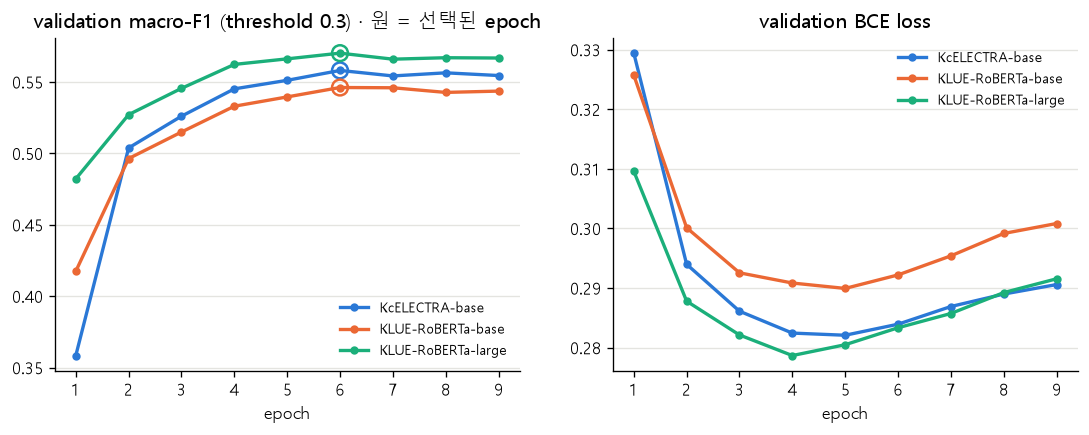

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, r in R.items():
    h = r["history"]
    axes[0].plot(h["epoch"], h["val_macro_f1@0.3"], marker="o", ms=4, lw=2, color=COLORS[name], label=name)
    axes[1].plot(h["epoch"], h["val_loss"], marker="o", ms=4, lw=2, color=COLORS[name], label=name)
    b = r["info"]["best_epoch"]
    axes[0].scatter([b], [h.loc[h["epoch"] == b, "val_macro_f1@0.3"]], s=90, facecolor="none", edgecolor=COLORS[name], lw=1.5, zorder=4)
axes[0].set_title("validation macro-F1 (threshold 0.3) · 원 = 선택된 epoch")
axes[1].set_title("validation BCE loss")
for a in axes:
    a.set_xlabel("epoch")
    a.grid(axis="y", color="#e4e4e0", lw=0.8)
    a.legend(frameon=False, fontsize=8.5)
save_fig(fig, FIG / "learning_curves.png")
plt.show()

**결과 해석**

- 세 모델 모두 **6 epoch을 선택**했고 9 epoch에서 조기 종료했다. validation loss는 4~5 epoch에서 가장 낮고 이후 오른다. 과적합 양상은 세 모델이 비슷하다.
- large는 1 epoch부터 macro-F1이 0.48로 가장 높고, 모든 epoch에서 앞선다. KLUE-base는 2 epoch 이후 validation loss가 가장 높다.

## 4. 차이가 우연인지: paired bootstrap

같은 test 샘플을 복원추출로 2,000번 다시 뽑아, 매번 세 모델의 macro-F1(라벨별 threshold)을 계산한다.
KcELECTRA 대비 차이의 95% 구간이 0을 포함하지 않으면, 이 test 데이터 기준으로 차이가 안정적이라고 본다.
seed를 바꾼 반복 학습의 변동은 이 구간에 들어 있지 않다(학습 1회씩).

In [5]:
rng = np.random.default_rng(0)
B = 2000
yt = R[BASE]["y"]["test"].astype(bool)
preds = {n: M.binarize(r["probs"]["test"], np.array(r["th"]["per_label"])).astype(bool) for n, r in R.items()}


def macro_f1(y, p):
    tp = (y & p).sum(0); fp = (~y & p).sum(0); fn = (y & ~p).sum(0)
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0).mean()


boot = {n: np.empty(B) for n in R}
for b in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    for n in R:
        boot[n][b] = macro_f1(yt[idx], preds[n][idx])
rows = []
for n in R:
    point = macro_f1(yt, preds[n])
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    d = boot[n] - boot[BASE]
    rows.append({"모델": n, "macro-F1": point, "95% 구간": f"[{lo:.4f}, {hi:.4f}]",
                 f"{BASE} 대비 차이": point - macro_f1(yt, preds[BASE]),
                 "차이 95% 구간": "-" if n == BASE else f"[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]",
                 "차이>0 비율": "-" if n == BASE else f"{(d > 0).mean():.1%}"})
boot_df = pd.DataFrame(rows)
show_fmt(boot_df, {"macro-F1": "{:.4f}", f"{BASE} 대비 차이": "{:+.4f}"}, index=False)

,모델,macro-F1,95% 구간,KcELECTRA-base 대비 차이,차이 95% 구간,차이>0 비율
0,KcELECTRA-base,0.5671,"[0.5612, 0.5727]",+0.0000,-,-
1,KLUE-RoBERTa-base,0.5606,"[0.5546, 0.5663]",-0.0065,"[-0.0112, -0.0018]",0.2%
2,KLUE-RoBERTa-large,0.5746,"[0.5687, 0.5805]",+0.0074,"[+0.0024, +0.0127]",99.9%


**결과 해석**

- **KLUE-large − KcELECTRA = +0.0074**, 95% 구간 [+0.0024, +0.0127]. 재표본 99.9%에서 large가 높다. 이 test 데이터 기준으로 차이가 안정적이다.
- **KLUE-base − KcELECTRA = −0.0065**, 95% 구간 [−0.0112, −0.0018]. KLUE-base가 낮다는 것도 안정적이다.
- 단, 이 구간은 test 샘플 변동만 반영한다. 학습 1회(seed 42)씩이라 **학습 무작위성에 따른 변동은 포함되지 않는다**. 차이가 0.7%p 정도로 작으므로, 채택 전에 seed 2~3개 반복으로 확인하는 것이 좋다.

## 5. 라벨별 성능 비교

라벨별 F1(test, 각 모델의 라벨별 threshold). 그래프는 KcELECTRA F1 순으로 정렬했다.

그림 저장: ai/outputs/emotion/comparison/figures/per_label_f1_comparison.png | 글꼴 누락 없음


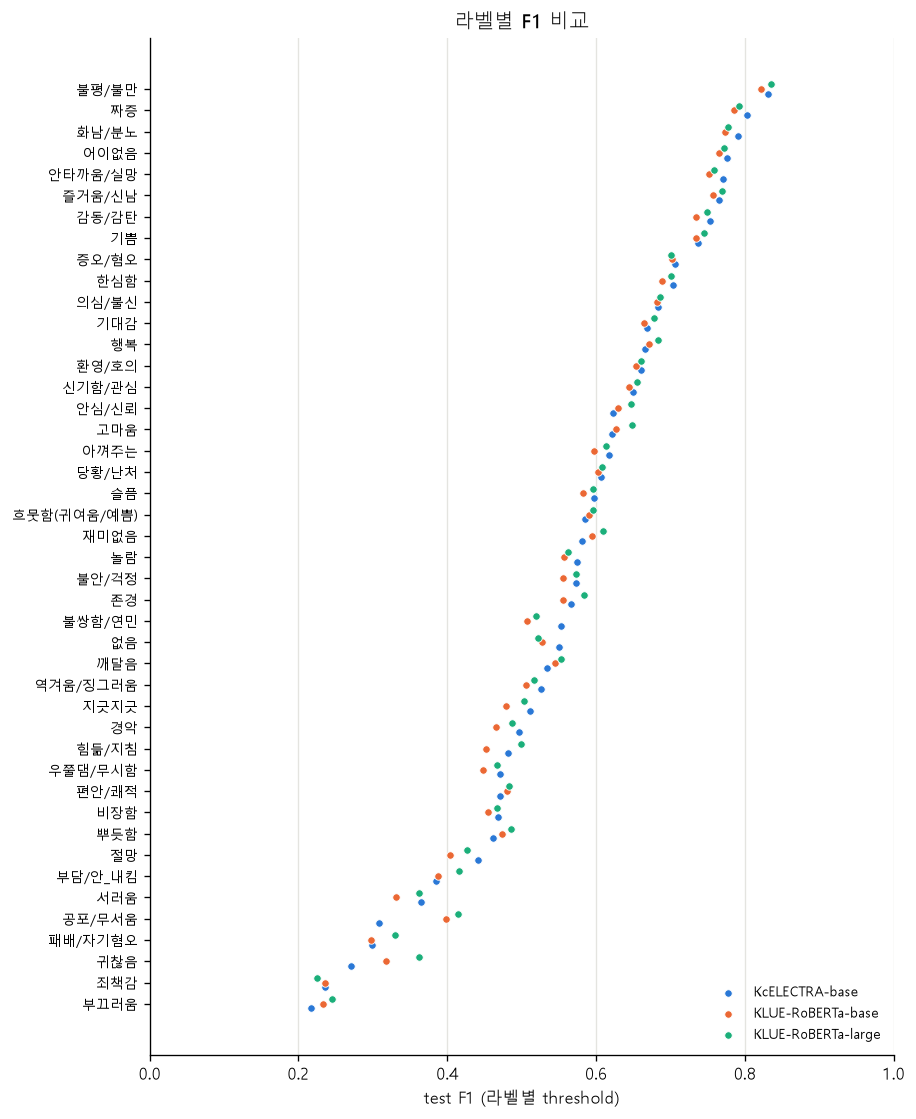

라벨별 최고 모델 수: {'KLUE-RoBERTa-large': 23, 'KcELECTRA-base': 21}

[희소 라벨 8개 (test 양성 적은 순)]


,label,support,KcELECTRA-base,KLUE-RoBERTa-base,KLUE-RoBERTa-large
0,죄책감,84,0.236,0.236,0.225
1,공포/무서움,164,0.308,0.399,0.415
2,패배/자기혐오,208,0.299,0.297,0.330
3,서러움,263,0.365,0.331,0.363
4,귀찮음,290,0.271,0.317,0.362
5,부끄러움,306,0.216,0.233,0.245
6,비장함,416,0.468,0.455,0.467
7,편안/쾌적,458,0.471,0.480,0.483


KLUE-RoBERTa-base - KcELECTRA-base: 라벨별 F1 차이 평균 -0.0065, 개선 12개 / 하락 32개, 희소 8개 평균 +0.0143
KLUE-RoBERTa-large - KcELECTRA-base: 라벨별 F1 차이 평균 +0.0074, 개선 23개 / 하락 21개, 희소 8개 평균 +0.0319


In [6]:
per = pd.DataFrame({"label": LABELS})
for n, r in R.items():
    per[n] = pd.read_csv(r["dir"] / "per_label_test.csv", encoding="utf-8-sig")["f1"].values
per["support"] = yt.sum(0)
per["최고 모델"] = per[list(R)].idxmax(axis=1)
per.to_csv(CMP / "per_label_f1_test.csv", index=False, encoding="utf-8-sig")
order = per.sort_values(BASE)

fig, ax = plt.subplots(figsize=(8, 11))
y = np.arange(len(order))
for k, n in enumerate(R):
    ax.scatter(order[n], y + (k - 1) * 0.22, s=20, color=COLORS[n], label=n, zorder=3, edgecolor="white", linewidth=0.5)
ax.set_yticks(y, order["label"], fontsize=8.5)
ax.set_xlim(0, 1)
ax.set_xlabel("test F1 (라벨별 threshold)")
ax.set_title("라벨별 F1 비교")
ax.grid(axis="x", color="#e4e4e0", lw=0.8)
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
save_fig(fig, FIG / "per_label_f1_comparison.png")
plt.show()

print("라벨별 최고 모델 수:", {k: int(v) for k, v in per["최고 모델"].value_counts().items()})
rare = per.nsmallest(8, "support")
print("\n[희소 라벨 8개 (test 양성 적은 순)]")
show_fmt(rare[["label", "support", *R]], {n: "{:.3f}" for n in R}, index=False)
for n in R:
    if n != BASE:
        diff = per[n] - per[BASE]
        print(f"{n} - {BASE}: 라벨별 F1 차이 평균 {diff.mean():+.4f}, 개선 {int((diff > 0).sum())}개 / 하락 {int((diff < 0).sum())}개, "
              f"희소 8개 평균 {diff[rare.index].mean():+.4f}")

**결과 해석**

- 라벨별로 가장 높은 모델은 KLUE-large 23개, KcELECTRA 21개다(KLUE-base 0개). large의 개선은 고르게 크지 않고, 일부 라벨에 몰려 있다.
- **희소 라벨에서 large의 이득이 크다**: 희소 8개 평균 +0.032. 귀찮음 0.271→0.362, 공포/무서움 0.308→0.415, 패배/자기혐오 0.299→0.330, 부끄러움 0.216→0.245. 죄책감(test 84건)만 0.236→0.225로 조금 낮아졌다.
- KcELECTRA는 ‘없음’, 불쌍함/연민 같은 일부 라벨에서 여전히 앞선다. 두 모델이 잘하는 라벨이 달라 앙상블 여지가 있다(10절).

## 6. 행성 관점 성능

행성 외형은 10개 감정 그룹 + ‘없음’ 기준이다(03 노트북). 모델별로 (1) 그룹 단위 macro-F1(‘없음’ 포함 11개), (2) 행성 기본색(주 그룹) 일치율을 비교한다.
정답 주 그룹은 원시 주석(`raw.json`)에서 평가자 선택이 가장 많은 그룹이며, 동점이면 그중 하나만 맞혀도 일치로 본다.
기본색 일치율은 실제 매핑처럼 ‘없음’을 뺀 10개 그룹 중에서 고르므로, ‘없음’까지 포함해 계산한 02 노트북 값과 정의가 조금 다르다.

In [7]:
from src.data.kote_load import load_raw_annotations
from src.data.labels import rater_vote_counts

groups = MAPPING["groups"] + [{"name": "없음", "labels": [MAPPING["neutral"]["label"]]}]
gidx = [[LABELS.index(l) for l in g["labels"]] for g in groups]
raw = load_raw_annotations(P.raw_kote)
name_to_id = {n: i for i, n in enumerate(LABELS)}
votes = np.stack([rater_vote_counts(raw[i]["labels"], name_to_id, len(LABELS)) for i in R[BASE]["ids"]["test"]])
Vg = np.stack([votes[:, ix].max(1) for ix in gidx[:-1]], 1)     # '없음' 제외 10개 그룹
truth_top = Vg == Vg.max(1, keepdims=True)
Yg = np.stack([yt[:, ix].max(1) for ix in gidx], 1)

rows, gf1 = [], {}
for n, r in R.items():
    p = r["probs"]["test"]
    Pg = np.stack([preds[n][:, ix].max(1) for ix in gidx], 1)
    c = M.per_label_counts(Yg, Pg)
    gf1[n] = c["f1"]
    Sg = np.stack([p[:, ix].max(1) for ix in gidx[:-1]], 1)
    rank = np.argsort(-Sg, 1)
    top1 = truth_top[np.arange(len(p)), rank[:, 0]]
    top2 = top1 | truth_top[np.arange(len(p)), rank[:, 1]]
    rows.append({"모델": n, "그룹 macro-F1": c["f1"].mean(), "기본색 일치 top-1": top1.mean(), "top-2": top2.mean()})
show_fmt(pd.DataFrame(rows), {"그룹 macro-F1": "{:.4f}", "기본색 일치 top-1": "{:.1%}", "top-2": "{:.1%}"}, index=False)
gtab = pd.DataFrame(gf1, index=[g["name"] for g in groups])
show_fmt(gtab.reset_index().rename(columns={"index": "그룹"}), {n: "{:.3f}" for n in R}, index=False)

,모델,그룹 macro-F1,기본색 일치 top-1,top-2
0,KcELECTRA-base,0.7107,68.2%,86.6%
1,KLUE-RoBERTa-base,0.7032,67.0%,85.4%
2,KLUE-RoBERTa-large,0.7132,69.6%,87.5%


,그룹,KcELECTRA-base,KLUE-RoBERTa-base,KLUE-RoBERTa-large
0,기쁨·즐거움,0.825,0.816,0.828
1,감사·애정,0.822,0.812,0.826
2,평온·안심,0.643,0.656,0.670
3,기대·호기심,0.808,0.805,0.809
4,분노·불만,0.889,0.876,0.883
5,혐오·불신,0.833,0.823,0.821
6,슬픔·상실,0.799,0.787,0.796
7,불안·당황,0.717,0.710,0.716
8,지침·무기력,0.597,0.589,0.622
9,부끄러움·자책,0.334,0.334,0.352


**결과 해석**

- 그룹 단위 macro-F1은 large 0.713, KcELECTRA 0.711로 거의 같다. 그러나 **행성 기본색 일치율**은 large가 69.6%(top-2 87.5%)로 KcELECTRA 68.2%(86.6%)보다 높다.
- large는 희소·저성능 그룹에서 개선이 크다: 지침·무기력 0.597→0.622, 평온·안심 0.643→0.670, 부끄러움·자책 0.334→0.352. 반대로 ‘없음’은 0.551→0.521로 낮아졌다.
- 그룹 안의 라벨 혼동은 그룹 단위에서 사라지므로, 라벨 단위 차이(0.007)보다 그룹 단위 차이가 작게 나온다.

## 7. 토크나이저 차이: `[UNK]` 영향

KLUE 토크나이저는 정제된 문장으로 학습되어 댓글의 희귀 음절(예: 인터넷 줄임말·오타)과 자모 단독 문자를 `[UNK]`로 바꾸는 경우가 있다.
`[UNK]`가 생기는 test 샘플과 그렇지 않은 샘플에서 micro-F1을 나눠 본다.

In [8]:
from transformers import AutoTokenizer
from src.emotion.text import prepare_text

test_texts = pd.read_parquet(P.processed_kote / "test.parquet")["text"].map(prepare_text).tolist()
toks = {n: AutoTokenizer.from_pretrained(str(P.repo_root / r["info"]["checkpoint_dir"])) for n, r in R.items()}
has_unk = {}
rows = []
for n, tok in toks.items():
    ids = tok(test_texts, add_special_tokens=True)["input_ids"]
    has_unk[n] = np.array([tok.unk_token_id in x for x in ids])
    rows.append({"모델(토크나이저)": n, "토큰 수 중앙값": np.median([len(x) for x in ids]),
                 "[UNK] 포함 샘플": has_unk[n].mean()})
show_fmt(pd.DataFrame(rows), {"토큰 수 중앙값": "{:.0f}", "[UNK] 포함 샘플": "{:.1%}"}, index=False)

klue_unk = has_unk["KLUE-RoBERTa-base"]
rows = []
for n in R:
    for label, mask in [("KLUE [UNK] 있음", klue_unk), ("KLUE [UNK] 없음", ~klue_unk)]:
        m = M.multilabel_metrics(yt[mask].astype(np.int8), R[n]["probs"]["test"][mask], np.array(R[n]["th"]["per_label"]))
        rows.append({"모델": n, "샘플 구분": label, "n": int(mask.sum()), "micro-F1": m["micro_f1"]})
unk_df = pd.DataFrame(rows).pivot(index="모델", columns="샘플 구분", values="micro-F1")
unk_df["차이(있음-없음)"] = unk_df["KLUE [UNK] 있음"] - unk_df["KLUE [UNK] 없음"]
print(f"KLUE 기준 [UNK] 있음 {int(klue_unk.sum())}개 / 없음 {int((~klue_unk).sum())}개")
show_fmt(unk_df.reset_index(), {c: "{:+.4f}" if "차이" in c else "{:.4f}" for c in unk_df.columns}, index=False)

,모델(토크나이저),토큰 수 중앙값,[UNK] 포함 샘플
0,KcELECTRA-base,21,0.2%
1,KLUE-RoBERTa-base,26,10.2%
2,KLUE-RoBERTa-large,26,10.2%


KLUE 기준 [UNK] 있음 508개 / 없음 4492개


샘플 구분,모델,KLUE [UNK] 없음,KLUE [UNK] 있음,차이(있음-없음)
0,KLUE-RoBERTa-base,0.6348,0.6121,-0.0226
1,KLUE-RoBERTa-large,0.6486,0.6221,-0.0265
2,KcELECTRA-base,0.6420,0.6456,+0.0037


**결과 해석**

- KLUE 토크나이저로 test 샘플의 **10.2%(508개)에 `[UNK]`가 생긴다**(KcELECTRA 0.2%). 원인은 인터넷 말투의 희귀 음절, 오타, 자모 단독 문자다.
- `[UNK]`가 생기는 샘플에서 KLUE 모델의 micro-F1은 0.023~0.027 낮다. KcELECTRA는 같은 샘플에서 차이가 없다(+0.004).
- 즉 KLUE 계열은 댓글체 어휘에서 손해를 본다. large는 모델 크기로 이를 상쇄하고 전체 성능이 더 높다. 일기에 신조어·줄임말이 많다면 이 약점이 다시 커질 수 있다.

## 8. 서비스 관점: 모델 크기와 추론 속도

일기 저장 시 서버에서 감정 분석을 돌린다고 가정하고, 모델 파일 크기와 추론 속도를 잰다.
- GPU: test 1,000개를 batch 64로 처리한 처리량
- CPU: 일기 1개를 처리하는 지연 시간 중앙값(가상 일기 12개 × 3회). 서버에 GPU가 없을 수 있으므로 함께 본다.

측정값은 이 PC(RTX 4060 Ti, 이 노트북 실행 시점의 부하) 기준이며 서버 환경에서는 달라진다.

In [9]:
from src.emotion.predict import EmotionPredictor

demo = load_json(P.configs / "demo_diaries.json")["diaries"]
demo_texts = [d["text"] for d in demo]
rows, demo_probs = [], {}
for n, r in R.items():
    ck = P.repo_root / r["info"]["checkpoint_dir"]
    size_mb = sum(f.stat().st_size for f in ck.glob("*.safetensors")) / 1e6
    row = {"모델": n, "가중치 크기(MB)": size_mb}
    if torch.cuda.is_available():
        pg = EmotionPredictor(ck, device="cuda")
        pg.predict_proba(test_texts[:64])                       # 예열
        t0 = time.perf_counter(); pg.predict_proba(test_texts[:1000]); dt = time.perf_counter() - t0
        row["GPU 처리량(개/초)"] = 1000 / dt
        demo_probs[n] = pg.predict_proba(demo_texts)
        del pg
        torch.cuda.empty_cache()
    pc = EmotionPredictor(ck, device="cpu")
    pc.predict_proba(demo_texts[:1])
    lat = []
    for _ in range(3):
        for t in demo_texts:
            t0 = time.perf_counter(); pc.predict_proba([t]); lat.append(time.perf_counter() - t0)
    row["CPU 지연(ms/개, 중앙값)"] = 1000 * np.median(lat)
    if n not in demo_probs:
        demo_probs[n] = pc.predict_proba(demo_texts)
    del pc
    rows.append(row)
speed = pd.DataFrame(rows)
show_fmt(speed, {"가중치 크기(MB)": "{:.0f}", "GPU 처리량(개/초)": "{:.0f}", "CPU 지연(ms/개, 중앙값)": "{:.0f}"}, index=False)
print("CPU 스레드 수:", torch.get_num_threads())

,모델,가중치 크기(MB),GPU 처리량(개/초),"CPU 지연(ms/개, 중앙값)"
0,KcELECTRA-base,498,1128,9
1,KLUE-RoBERTa-base,443,877,10
2,KLUE-RoBERTa-large,1347,290,31


CPU 스레드 수: 24


**결과 해석**

- 가중치 크기: KcELECTRA 498MB, KLUE-base 443MB, **KLUE-large 1,347MB**(약 2.7배)
- GPU 처리량: KcELECTRA 약 1,140개/초, KLUE-base 약 885개/초, **large 약 290개/초**(약 4배 느림)
- CPU 지연(일기 1개, 이 PC 24스레드 기준): base 계열 약 10ms, **large 약 31ms**
- 일기 저장 때 한 번 추론하는 서비스라면 세 모델 모두 충분히 빠르다. large는 메모리를 약 1.3GB 이상 더 쓰므로, 실제 서버(CPU·메모리)에서 다시 재야 한다.

## 9. 가상 일기 예측 비교

개발자가 쓴 가상 일기(실제 사용자 일기 아님)에 대한 모델별 상위 3개 감정. 정성 점검용이다.

In [10]:
rows = []
for k, d in enumerate(demo):
    row = {"id": d["id"], "의도": d["intended"]}
    for n in R:
        p = demo_probs[n][k]
        row[n] = ", ".join(f"{LABELS[j]} {p[j]:.2f}" for j in np.argsort(-p)[:3])
    rows.append(row)
pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame(rows))

,id,의도,KcELECTRA-base,KLUE-RoBERTa-base,KLUE-RoBERTa-large
0,d01,joy,"기쁨 0.98, 즐거움/신남 0.95, 행복 0.94","기쁨 0.95, 행복 0.92, 즐거움/신남 0.91","기쁨 0.97, 행복 0.92, 즐거움/신남 0.92"
1,d02,warmth,"기쁨 0.93, 고마움 0.92, 행복 0.90","고마움 0.88, 기쁨 0.82, 행복 0.81","고마움 0.87, 기쁨 0.87, 감동/감탄 0.85"
2,d03,calm,"기쁨 0.96, 즐거움/신남 0.94, 행복 0.92","편안/쾌적 0.74, 기쁨 0.68, 행복 0.59","편안/쾌적 0.95, 행복 0.85, 기쁨 0.80"
3,d04,curiosity,"기대감 0.96, 신기함/관심 0.94, 감동/감탄 0.90","기대감 0.94, 신기함/관심 0.93, 즐거움/신남 0.67","기대감 0.97, 즐거움/신남 0.78, 신기함/관심 0.77"
4,d05,anger,"짜증 0.96, 화남/분노 0.94, 불평/불만 0.91","불평/불만 0.96, 짜증 0.96, 화남/분노 0.87","짜증 0.98, 불평/불만 0.94, 화남/분노 0.93"
5,d06,sadness,"슬픔 0.96, 안타까움/실망 0.79, 불쌍함/연민 0.66","슬픔 0.94, 안타까움/실망 0.90, 불쌍함/연민 0.77","슬픔 0.94, 안타까움/실망 0.89, 불쌍함/연민 0.85"
6,d07,anxiety,"불안/걱정 0.82, 당황/난처 0.23, 의심/불신 0.21","불안/걱정 0.90, 당황/난처 0.30, 의심/불신 0.25","불안/걱정 0.95, 의심/불신 0.20, 공포/무서움 0.16"
7,d08,fatigue,"힘듦/지침 0.93, 짜증 0.76, 지긋지긋 0.71","힘듦/지침 0.87, 짜증 0.76, 불평/불만 0.67","힘듦/지침 0.94, 지긋지긋 0.80, 짜증 0.70"
8,d09,shame,"슬픔 0.95, 안타까움/실망 0.84, 불쌍함/연민 0.75","슬픔 0.89, 안타까움/실망 0.88, 불쌍함/연민 0.79","부끄러움 0.86, 안타까움/실망 0.72, 패배/자기혐오 0.65"
9,d10,contempt,"불평/불만 0.96, 안타까움/실망 0.95, 의심/불신 0.94","불평/불만 0.96, 안타까움/실망 0.96, 의심/불신 0.95","안타까움/실망 0.97, 의심/불신 0.96, 불평/불만 0.95"


**결과 해석**

- 가상 일기 12개(개발자 작성) 정성 비교다. **large가 일기 문장에서 의도에 더 가깝게 반응한다.**
  - 자책(d09): large만 부끄러움 0.86, 패배/자기혐오 0.65를 상위로 낸다. 두 base 모델은 슬픔으로 분류했다.
  - 편안함(d03): large는 편안/쾌적 0.95가 1위다. KcELECTRA는 기쁨이 1위였다.
  - 담담함(d11): large는 ‘없음’ 0.50으로 KcELECTRA(0.36)보다 높다.
- 기쁨과 아쉬움이 섞인 일기(d12)는 세 모델 모두 즐거움을 놓친다.
- 일기는 댓글보다 정제된 문장이라 일반 한국어로 사전학습한 KLUE가 유리했을 수 있다. 다만 12문장 정성 점검이므로 실제 일기로 확인해야 한다.

## 10. 앙상블 (추가 학습 없음)

저장된 예측 확률을 평균하는 가장 단순한 앙상블을 시험한다. 조합 선택과 라벨별 threshold 결정은 **validation에서만** 하고, test는 확인에만 쓴다.
사전학습 데이터와 어휘가 다른 모델(댓글 vs 일반 한국어)은 서로 다른 실수를 할 수 있어 보완 효과를 기대할 수 있다.

In [11]:
grid = M.threshold_grid(**R[BASE]["info"]["config"]["eval"]["threshold_grid"])
yv = R[BASE]["y"]["validation"]
combos = {
    "KcELECTRA-base": [BASE],
    "KLUE-RoBERTa-large": ["KLUE-RoBERTa-large"],
    "KcELECTRA + KLUE-large": [BASE, "KLUE-RoBERTa-large"],
    "KLUE-base + KLUE-large": ["KLUE-RoBERTa-base", "KLUE-RoBERTa-large"],
    "세 모델 평균": list(R),
}
rows, ens = [], {}
for cname, members in combos.items():
    pv = np.mean([R[m]["probs"]["validation"] for m in members], 0)
    pt = np.mean([R[m]["probs"]["test"] for m in members], 0)
    th = M.tune_per_label_thresholds(yv, pv, grid)
    mv, mt = M.multilabel_metrics(yv, pv, th), M.multilabel_metrics(yt.astype(np.int8), pt, th)
    ens[cname] = {"pred": M.binarize(pt, th).astype(bool), "probs": pt, "val": mv["macro_f1"]}
    rows.append({"조합": cname, "모델 수": len(members), "val macro-F1": mv["macro_f1"], "test macro-F1": mt["macro_f1"],
                 "test micro-F1": mt["micro_f1"], "test AUC": mt["macro_roc_auc"], "예측 라벨 수": mt["mean_pred_labels"]})
ens_df = pd.DataFrame(rows)
best_combo = ens_df.loc[ens_df[ens_df["모델 수"] > 1]["val macro-F1"].idxmax(), "조합"]
show_fmt(ens_df, {c: "{:.4f}" for c in ["val macro-F1", "test macro-F1", "test micro-F1", "test AUC"]} | {"예측 라벨 수": "{:.2f}"}, index=False)
print("validation 기준으로 고른 앙상블:", best_combo)

rng = np.random.default_rng(1)
diffs = {ref: np.empty(B) for ref in (BASE, "KLUE-RoBERTa-large")}
for b in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    e = macro_f1(yt[idx], ens[best_combo]["pred"][idx])
    for ref in diffs:
        diffs[ref][b] = e - macro_f1(yt[idx], ens[ref]["pred"][idx])
for ref, d in diffs.items():
    print(f"{best_combo} - {ref}: {np.mean(d):+.4f}, 95% 구간 [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}], 차이>0 {(d > 0).mean():.1%}")
ens_df.to_csv(CMP / "ensemble_test.csv", index=False, encoding="utf-8-sig")

,조합,모델 수,val macro-F1,test macro-F1,test micro-F1,test AUC,예측 라벨 수
0,KcELECTRA-base,1,0.5724,0.5671,0.6424,0.8708,9.68
1,KLUE-RoBERTa-large,1,0.5815,0.5746,0.6458,0.8742,9.36
2,KcELECTRA + KLUE-large,2,0.5914,0.5830,0.6561,0.8823,9.45
3,KLUE-base + KLUE-large,2,0.5815,0.5774,0.6495,0.8769,9.54
4,세 모델 평균,3,0.5899,0.5843,0.6561,0.8824,9.47


validation 기준으로 고른 앙상블: KcELECTRA + KLUE-large


KcELECTRA + KLUE-large - KcELECTRA-base: +0.0159, 95% 구간 [+0.0120, +0.0198], 차이>0 100.0%
KcELECTRA + KLUE-large - KLUE-RoBERTa-large: +0.0085, 95% 구간 [+0.0048, +0.0122], 차이>0 100.0%


**결과 해석**

- **KcELECTRA + KLUE-large 확률 평균**이 validation 기준 최고 조합(0.5914)이고, test macro-F1 **0.5830**, micro-F1 0.6561, AUC 0.8823이다.
- 단일 모델 대비 차이(paired bootstrap):
  - KcELECTRA보다 +0.0159, 95% 구간 [+0.0120, +0.0198]
  - KLUE-large보다 +0.0085, 95% 구간 [+0.0048, +0.0122]
  - 모델 하나를 키운 것(+0.007)보다 이득이 크다.
- 세 모델 평균은 test가 0.5843으로 비슷하지만, validation(0.5899)이 두 모델 조합보다 낮아 선택하지 않았다. KLUE-base + KLUE-large(0.5774)는 이득이 작다. **어휘·사전학습 데이터가 다른 모델끼리 섞을 때 효과가 크다.**
- 비용: 두 모델을 모두 돌려야 하므로 추론 시간과 메모리는 두 모델의 합이다(CPU 약 41ms, 가중치 약 1.8GB).

## 11. 결론

| 순위 | 구성 | test macro-F1 | 비고 |
|---|---|---:|---|
| 1 | KcELECTRA + KLUE-large 앙상블 | **0.583** | 가장 높음, 추론 비용 2배 |
| 2 | KLUE-RoBERTa-large | 0.575 | 단일 모델 최고, 희소 감정·일기 문장에 강함 |
| 3 | KcELECTRA-base | 0.567 | 가볍고 빠름, 댓글체 어휘에 강함 |
| 4 | KLUE-RoBERTa-base | 0.561 | 가장 빠른 학습, `[UNK]` 영향 |

- **모델 크기는 도움이 된다**(base → large, +0.014). **사전학습 데이터는 도메인에 맞아야 한다**(같은 크기에서는 댓글로 학습한 KcELECTRA > KLUE-base).
- **서로 다른 모델의 앙상블이 가장 효과적이다**(+0.016 vs KcELECTRA).
- 절대 성능은 여전히 macro-F1 0.58 수준이다. KOTE 라벨 자체의 평가자 간 불일치가 커서, 모델 교체만으로 크게 오르기는 어렵다.

**제안**
1. 서비스 1차 모델: 서버 자원이 허락하면 **KLUE-large 단독 또는 KcELECTRA+KLUE-large 앙상블**, 가벼워야 하면 KcELECTRA
2. 채택 전 seed 2~3개 반복 학습으로 차이가 학습 무작위성보다 큰지 확인
3. 선택한 모델로 행성 매핑의 고리 기준(`active_min`)을 03 노트북 4절 방식으로 다시 보정
4. 다음 개선 실험(클래스 가중치, soft label)은 선택한 모델 위에서 진행